# Corporate credit risk: a reproducible walkthrough

**Independent work sample; all borrower and macroeconomic data are synthetic.**
This notebook follows the committed data from source reconciliation to logistic estimation,
out-of-time validation and conditional scenario scoring. The Python pipeline is the executed
reference. Separate R and SAS implementations have not been run in their native environments.

Run `python -m src.pipeline` from the repository root to recreate the inputs and reference outputs.
Cells below can then be rerun in Jupyter. This notebook is built by executing the calculation
cells in sequence; figures are embedded from the pipeline's saved charts.


In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score, brier_score_loss

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src.pipeline import FEATURES, SCENARIOS, LGD, fit_logistic, predict_logistic, stress_frame

data = pd.read_csv(ROOT / "data/processed/model_data.csv")
summary = json.loads((ROOT / "outputs/metrics.json").read_text())
print(f"Complete records: {len(data):,}; unique borrowers: {data.borrower_id.nunique():,}")
print("Predictors:", ", ".join(FEATURES))


Complete records: 6,398; unique borrowers: 6,398
Predictors: leverage, dscr, interest_rate_pct, gdp_growth_pct, past_due_30d


## 1. Reconcile the sources before fitting

The generator intentionally inserts one exact duplicate and two missing financial values.
Complete-case exclusions follow a fixed rule; there is no label-driven selection.
Financial and repayment tables join one-to-one on borrower/date. The macro table joins
many-to-one on date. Conflicting duplicate keys cause a failure.


In [2]:
audit = pd.read_csv(ROOT / "outputs/data_quality_audit.csv")
recon = json.loads((ROOT / "outputs/reconciliation.json").read_text())
print(audit[["step", "count"]].to_string(index=False))
assert recon["raw_rows"] - recon["exact_duplicate_rows"] - recon["excluded_incomplete"] == len(data)
debt_gap = recon["unique_debt_cny_m"] - recon["excluded_debt_cny_m"] - data.debt_cny_m.sum()
assert abs(debt_gap) < 1e-6
print(f"Debt reconciliation difference: {debt_gap:.9f} CNY million")


                    step  count
      raw_financial_rows   6401
exact_duplicates_removed      1
   matched_borrower_rows   6400
incomplete_rows_excluded      2
              model_rows   6398
Debt reconciliation difference: 0.000000000 CNY million


## 2. Respect outcome availability

Each row has a forward 12-month default label. Training snapshots end in 2019, their labels
mature in 2020, validation occurs in 2021, and its labels mature in 2022. The models and
thresholds are frozen before the 2023–2024 test snapshots. Embargo years are not used for
model fitting, threshold selection or performance evaluation. All test labels mature by end-2025.


In [3]:
train = data.loc[data.split.eq("train")].copy()
validation = data.loc[data.split.eq("validation")].copy()
test = data.loc[data.split.eq("test")].copy()
print(data.groupby("split").agg(records=("borrower_id", "size"),
      first_snapshot=("snapshot_date", "min"), last_snapshot=("snapshot_date", "max")).to_string())
assert set(train.borrower_id).isdisjoint(test.borrower_id)
assert pd.to_datetime(train.snapshot_date).max() + pd.DateOffset(years=1) < pd.to_datetime(validation.snapshot_date).min()
assert pd.to_datetime(validation.snapshot_date).max() + pd.DateOffset(years=1) < pd.to_datetime(test.snapshot_date).min()


            records first_snapshot last_snapshot
split                                           
embargo        1600     2020-03-31    2022-12-31
test           1598     2023-03-31    2024-12-31
train          2400     2017-03-31    2019-12-31
validation      800     2021-03-31    2021-12-31


## 3. Estimate the multivariable logistic model

The model estimates one binary response using five numeric predictors. The fit uses
unpenalized maximum likelihood with explicit gradient and Hessian. HC1 standard errors
use an independent-observation sandwich estimator. The coefficients describe a synthetic
predictive association, not a causal relationship or a bank policy.

Interest rate and GDP growth use percentage-point units. Leverage and DSCR use ratio units.


In [4]:
beta, coefficients, diagnostics = fit_logistic(train)
print(coefficients[["term", "coefficient", "std_error", "p_value", "odds_ratio"]].round(5).to_string(index=False))
print("Maximum absolute score:", f"{diagnostics['max_absolute_score']:.3g}")
print("Minimum Hessian eigenvalue:", round(diagnostics["minimum_hessian_eigenvalue"], 4))
print("Maximum training VIF:", round(summary["maximum_training_vif"], 3))


             term  coefficient  std_error  p_value  odds_ratio
        Intercept     -2.31573    0.41307  0.00000     0.09869
         leverage      2.79962    0.34360  0.00000    16.43834
             dscr     -0.51740    0.07169  0.00000     0.59607
interest_rate_pct      0.16665    0.08787  0.05787     1.18134
   gdp_growth_pct     -0.07197    0.05297  0.17422     0.93055
     past_due_30d      1.49610    0.19189  0.00000     4.46425
Maximum absolute score: 9.28e-08
Minimum Hessian eigenvalue: 5.6367
Maximum training VIF: 1.423


## 4. Check the untouched test cohort

The decision tree is selected using validation AUC. Each classifier's threshold maximizes
validation F1 on a fixed grid from 0.01 to 0.80, with the larger threshold breaking ties.
The test set is not used to select parameters or thresholds. AUC measures ranking; Brier
score and calibration examine probability quality. Neither establishes business usefulness alone.


In [5]:
reference = pd.read_csv(ROOT / "outputs/test_predictions.csv")
recomputed = predict_logistic(test, beta)
assert reference.borrower_id.tolist() == test.borrower_id.tolist()
assert np.max(np.abs(recomputed - reference.pd_logistic.to_numpy())) < 1e-7
metrics = pd.read_csv(ROOT / "outputs/model_metrics.csv")
columns = ["model", "n", "roc_auc", "average_precision", "brier_score", "threshold", "precision", "recall"]
print(metrics.loc[metrics.split.eq("test"), columns].round(4).to_string(index=False))
print("Observed test default rate:", f"{test.default_12m.mean():.2%}")
print("Recomputed logistic AUC:", round(roc_auc_score(test.default_12m, recomputed), 6))
print("Recomputed logistic Brier:", round(brier_score_loss(test.default_12m, recomputed), 6))


        model    n  roc_auc  average_precision  brier_score  threshold  precision  recall
     Logistic 1598   0.7446             0.4542       0.1539       0.25     0.4239  0.5644
Decision tree 1598   0.7107             0.3851       0.1594       0.21     0.3698  0.6301
Observed test default rate: 22.84%
Recomputed logistic AUC: 0.744557
Recomputed logistic Brier: 0.153904


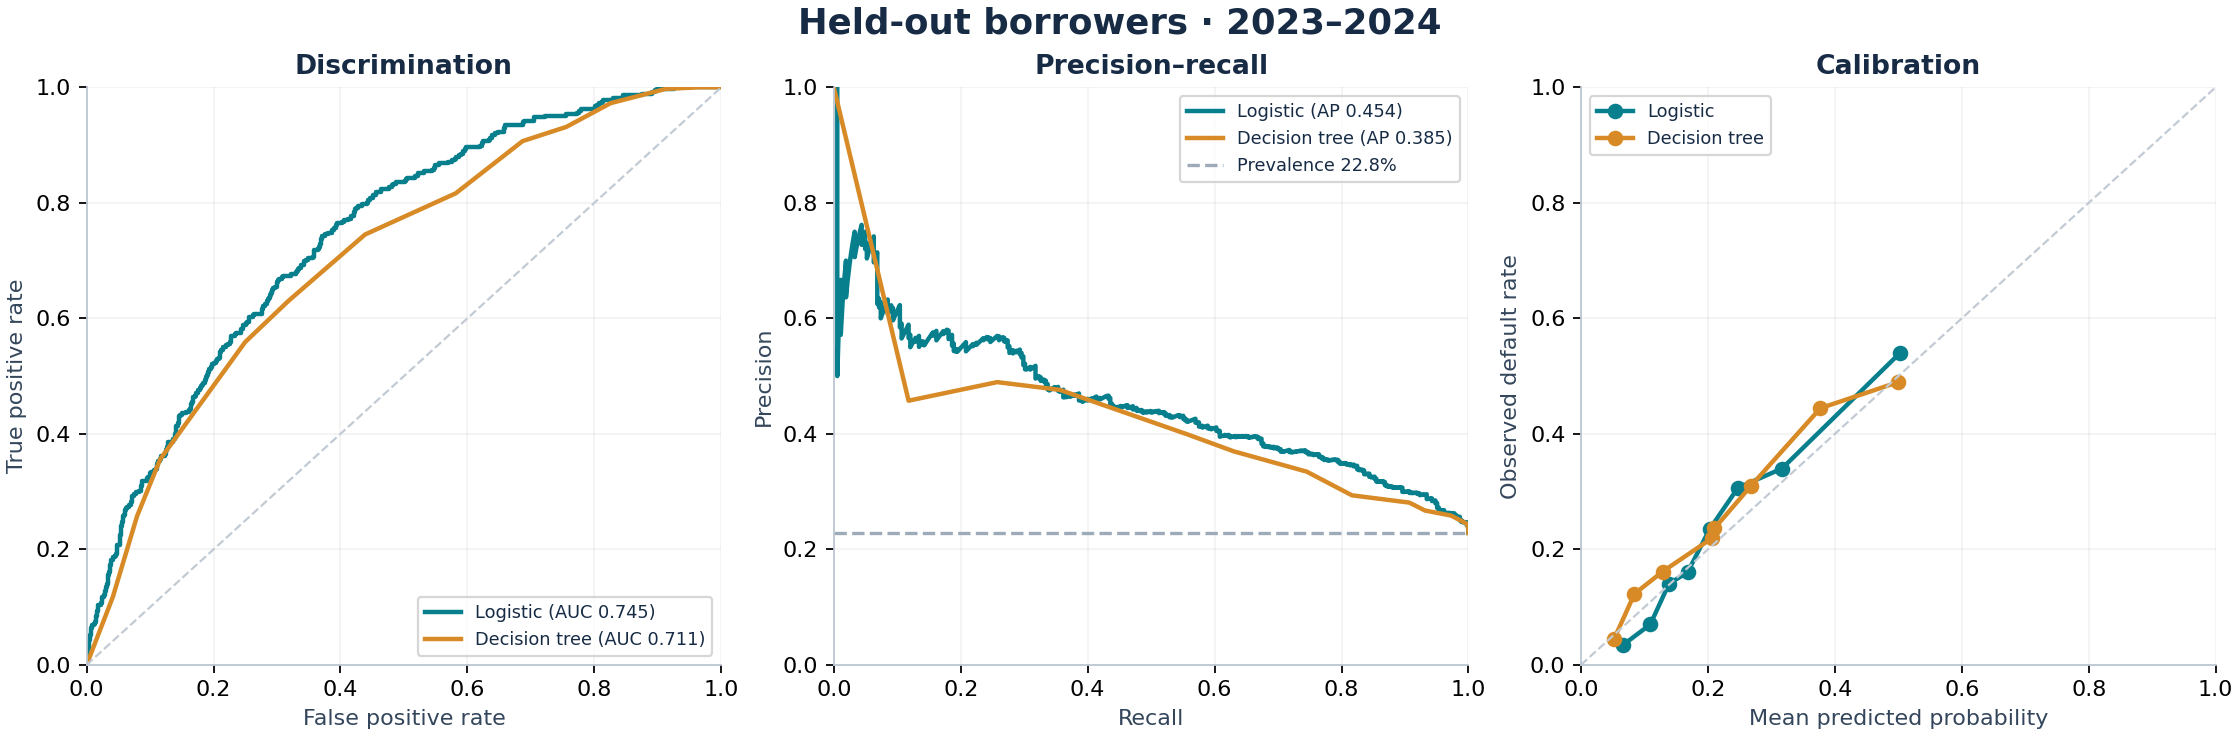

The outcome generator has a logistic form, so the experiment favors that specification.
The high simulated default prevalence was not calibrated to an actual bank. The comparison
demonstrates evaluation mechanics and cannot establish real-world model superiority.


## 5. Re-score explicit scenarios

Scenario shocks modify features for the same test borrowers while coefficients, exposure
and past delinquency stay fixed. Mean PD is an unweighted average; the loss proxy weights
each borrower's PD by their debt. LGD is an assumed 45%. This is a conditional sensitivity
exercise, not a causal macro forecast, lending recommendation or complete IFRS 9 model.


In [6]:
scenario_rows = []
for name, shock in SCENARIOS.items():
    changed = stress_frame(test, shock)
    probabilities = predict_logistic(changed, beta)
    scenario_rows.append({"scenario": name, "borrowers": len(changed),
        "mean_pd": probabilities.mean(),
        "loss_proxy_cny_m": np.sum(test.debt_cny_m.to_numpy() * probabilities * LGD)})
scenario_table = pd.DataFrame(scenario_rows)
print(scenario_table.round(4).to_string(index=False))
print("Assumptions:")
print(pd.DataFrame(SCENARIOS).T.to_string())


scenario  borrowers  mean_pd  loss_proxy_cny_m
    Base       1598   0.2190         9782.1108
 Adverse       1598   0.3197        13969.1043
  Severe       1598   0.4419        18811.1619
Assumptions:
         leverage_add  dscr_multiplier  interest_rate_add_pp  gdp_growth_add_pp
Base             0.00             1.00                   0.0                0.0
Adverse          0.05             0.85                   1.0               -2.0
Severe           0.10             0.70                   2.0               -4.0


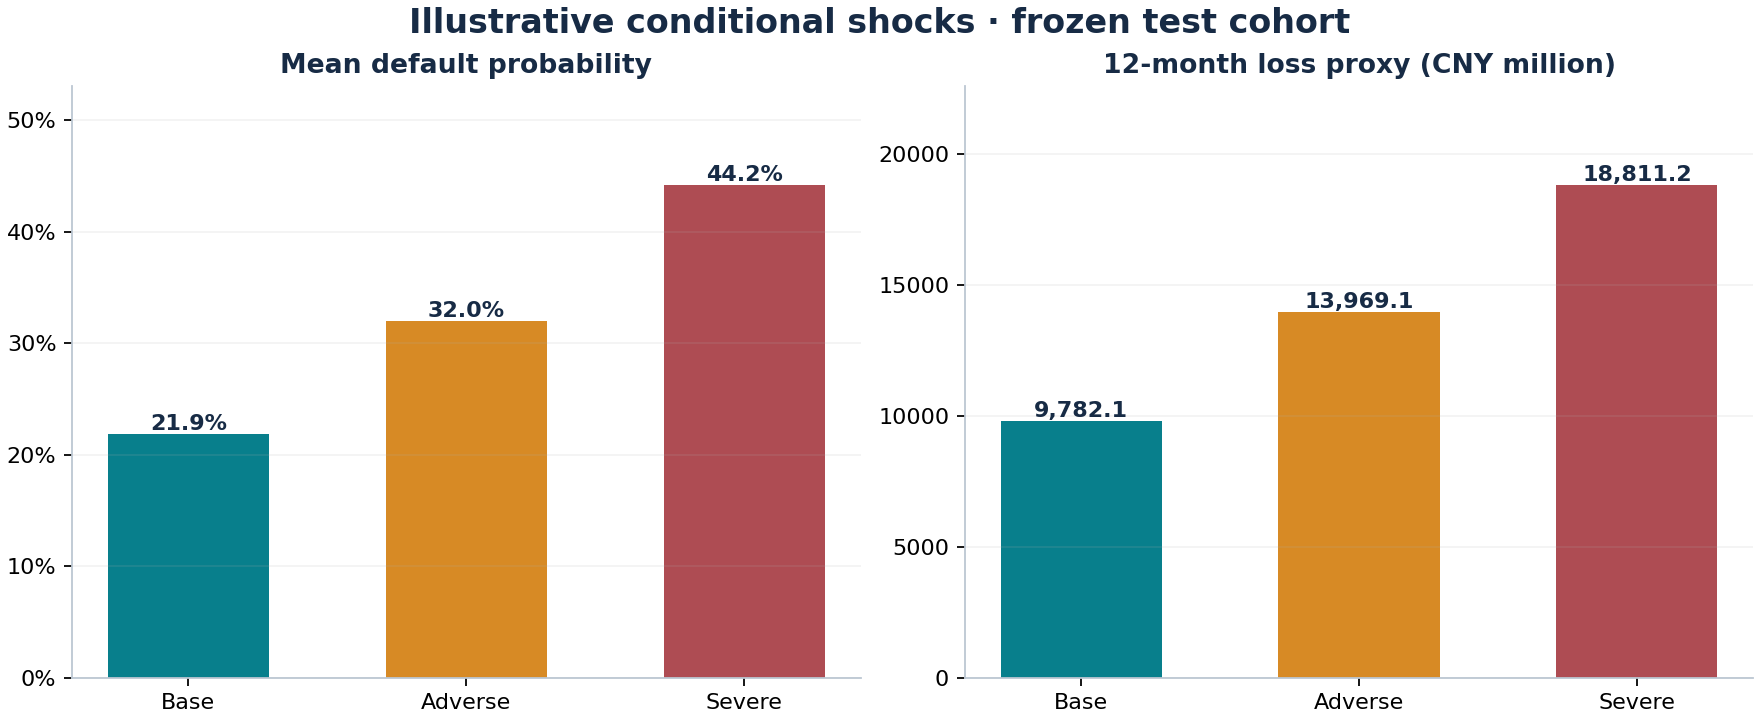

## 6. Follow the result into Office

- [Excel review](../outputs/Credit_Risk_Review.xlsx): inspect formulas, change the active scenario and trace summaries to rows.
- [Word memorandum](../outputs/Credit_Risk_Memo.docx): review model results and limitations.
- [PowerPoint deck](../outputs/Credit_Risk_Review.pptx): present the analytical findings.
- [Optional Office modules](../excel/OFFICE_EXTENSIONS.md): manually install Power Query, DAX and VBA examples.

The native R, SAS and Office extension runtimes were not available for execution. Their source
and setup instructions are supplied without claiming verified cross-engine equivalence.
